# Notebook 2: Building the Network

**Goal:** Turn the filtered nodes/edges from Notebook 1 into an actual
`networkx` graph, and get first-pass structural stats — degree distribution,
connected components, a geographically-laid-out plot — before we add the
temporal dimension in Notebook 3.

In [ ]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import os

os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)


if os.path.exists("/kaggle/input"):
    NB1_DIR = "/kaggle/input/nb1-eda/data"  
else:
    NB1_DIR = "data"

plt.rcParams["figure.figsize"] = (10, 6)

## 2.1 Load filtered tables from Notebook 1

In [2]:
nodes = pd.read_csv(f"{NB1_DIR}/nodes_corridor.csv", low_memory=False)
edges_all = pd.read_csv(f"{NB1_DIR}/edges_corridor.csv", low_memory=False)
edges_trade = pd.read_csv(f"{NB1_DIR}/edges_trade_relevant.csv", low_memory=False)

print(f"Nodes available: {len(nodes):,}")
print(f"All corridor edges: {len(edges_all):,}")
print(f"Trade-relevant edges: {len(edges_trade):,}")

Nodes available: 30,461
All corridor edges: 12,431
Trade-relevant edges: 4,483


## 2.2 Build the graph

We use the **trade-relevant edge set** (route_next, connection, flows_into,
succeeds, abuts, bounds, near) rather than all edges — spatial-containment
edges like `at`/`on`/`part_of_*` would just connect a temple to the city
it's in, which isn't a trade relationship and would badly distort centrality
scores.

In [3]:
G = nx.Graph()

for _, row in nodes.iterrows():
    G.add_node(
        row["id"],
        title=row["title"],
        lon=row["representative_longitude"],
        lat=row["representative_latitude"],
    )

edge_count_added = 0
for _, row in edges_trade.iterrows():
    src, dst = row["place_id"], row["connects_to_id"]
    if src in G.nodes and dst in G.nodes and src != dst:
        G.add_edge(src, dst, connection_type=row["connection_type"])
        edge_count_added += 1

print(f"Graph built: {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges")
print(f"(added {edge_count_added:,} edges; some were dropped as self-loops or duplicates)")

Graph built: 30,461 nodes, 4,469 edges
(added 4,482 edges; some were dropped as self-loops or duplicates)


## 2.3 Connected components

A graph built from real historical data is almost never fully connected —
many places only have a spatial-containment edge (which we excluded) and no
recorded trade/route relationship. Let's see how fragmented this is.

In [4]:
components = list(nx.connected_components(G))
components.sort(key=len, reverse=True)

print(f"Total connected components: {len(components):,}")
print(f"Largest component size: {len(components[0]):,} nodes "
      f"({len(components[0])/G.number_of_nodes():.1%} of all nodes)")
print(f"Top 10 component sizes: {[len(c) for c in components[:10]]}")
print(f"Isolated nodes (no trade-relevant edges at all): "
      f"{sum(1 for c in components if len(c) == 1):,}")

Total connected components: 26,477
Largest component size: 2,608 nodes (8.6% of all nodes)
Top 10 component sizes: [2608, 71, 58, 31, 31, 24, 20, 18, 16, 16]
Isolated nodes (no trade-relevant edges at all): 25,811


In [5]:
G_lcc = G.subgraph(components[0]).copy()
print(f"Working graph (largest component): {G_lcc.number_of_nodes():,} nodes, "
      f"{G_lcc.number_of_edges():,} edges")

Working graph (largest component): 2,608 nodes, 3,039 edges


## 2.4 Degree distribution

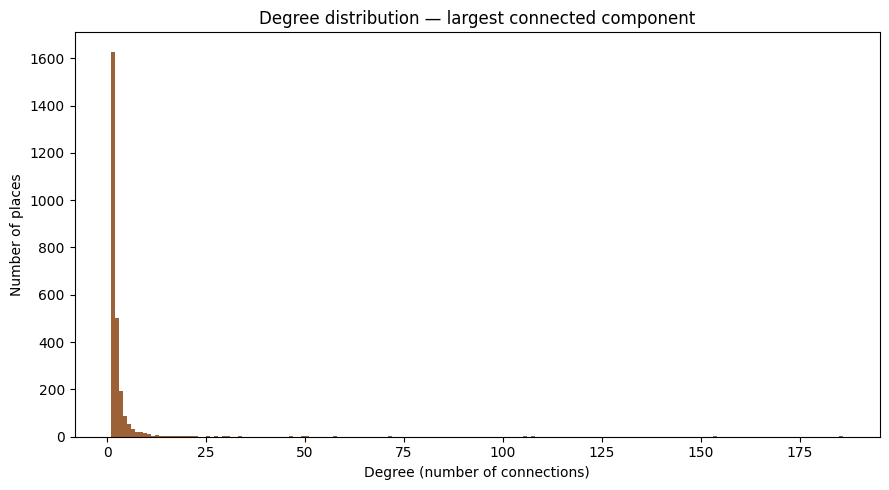

Mean degree: 2.33
Max degree: 185
Highest-degree node: Sardinia (island) (degree 185)


In [6]:
degrees = [d for _, d in G_lcc.degree()]

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(degrees, bins=range(1, max(degrees) + 2), color="#8B4513", alpha=0.85)
ax.set_xlabel("Degree (number of connections)")
ax.set_ylabel("Number of places")
ax.set_title("Degree distribution — largest connected component")
plt.tight_layout()
plt.savefig("outputs/04_degree_distribution.png", dpi=120)
plt.show()

print(f"Mean degree: {np.mean(degrees):.2f}")
print(f"Max degree: {max(degrees)}")
top_hub = max(G_lcc.nodes, key=lambda n: G_lcc.degree(n))
print(f"Highest-degree node: {G_lcc.nodes[top_hub]['title']} (degree {G_lcc.degree(top_hub)})")

## 2.5 Geographic plot of the largest component

Using each place's real lat/lon as its plot position (not a force-directed
layout) — this should visually resemble an actual trade network map.

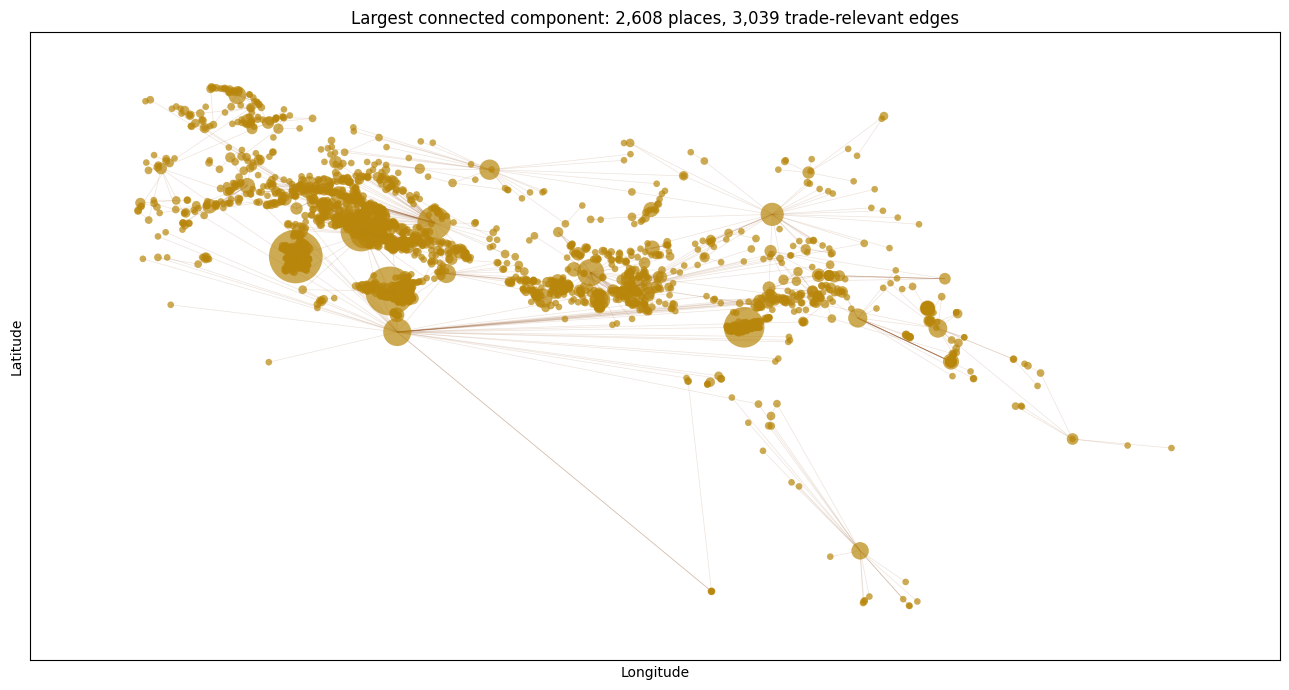

In [7]:
pos = {n: (G_lcc.nodes[n]["lon"], G_lcc.nodes[n]["lat"]) for n in G_lcc.nodes}
node_sizes = [15 + G_lcc.degree(n) * 8 for n in G_lcc.nodes]

fig, ax = plt.subplots(figsize=(13, 7))
nx.draw_networkx_edges(G_lcc, pos, ax=ax, alpha=0.15, width=0.5, edge_color="#8B4513")
nx.draw_networkx_nodes(G_lcc, pos, ax=ax, node_size=node_sizes,
                        node_color="#B8860B", alpha=0.7, linewidths=0)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(f"Largest connected component: {G_lcc.number_of_nodes():,} places, "
             f"{G_lcc.number_of_edges():,} trade-relevant edges")
plt.tight_layout()
plt.savefig("outputs/05_lcc_geographic.png", dpi=120)
plt.show()

## 2.6 Where does Central Asia sit in this raw structure?

Quick sanity check before we move to centrality analysis: are Merv, Bukhara,
etc. actually inside the largest connected component, or did they get
stranded as isolated nodes?

In [8]:
key_sites = ["Merv", "Margiana", "Samarkand", "Bukhara", "Nisa", "Bactra"]
for site in key_sites:
    matches = nodes[nodes["title"].str.contains(site, case=False, na=False)]
    for _, row in matches.iterrows():
        in_lcc = row["id"] in G_lcc.nodes
        deg = G_lcc.degree(row["id"]) if in_lcc else G.degree(row["id"]) if row["id"] in G.nodes else 0
        print(f"  {row['title']:35s} in LCC: {str(in_lcc):5s}  degree: {deg}")

  Margiana/Margush/Merv               in LCC: False  degree: 0
  Alexandria/Antiochia/Merv           in LCC: False  degree: 0
  Gyaur-Kala, Merv                    in LCC: False  degree: 0
  Margiana/Margush/Merv               in LCC: False  degree: 0
  Bukhara                             in LCC: False  degree: 1
  New Nisa                            in LCC: False  degree: 0
  Nisaki                              in LCC: False  degree: 0
  Nisa(ia)/Parthaunisa/Mithradatkert/Shahr-ram-Peroz in LCC: False  degree: 0
  Nisa                                in LCC: False  degree: 0
  Anisa                               in LCC: False  degree: 1
  Old Nisa                            in LCC: False  degree: 0
  Arnisa                              in LCC: False  degree: 1
  Thinisa?/Tuneiza?/Tunisa?           in LCC: False  degree: 0
  Venisami                            in LCC: False  degree: 0
  Nisāya / Nisaian plain              in LCC: False  degree: 1
  Enisala                             in

## 2.7 Save the graph for Notebook 3

In [9]:
nx.write_graphml(G_lcc, "data/silk_road_graph_lcc.graphml")
print("Saved graph to data/silk_road_graph_lcc.graphml")

Saved graph to data/silk_road_graph_lcc.graphml


## Summary

- Built a graph using only trade/route-relevant edges (not spatial
  containment), which is the structurally meaningful choice
- The graph is highly fragmented — most nodes have no recorded
  route-relevant connection, so we proceed with the largest connected
  component only
- Central Asian sites' presence/absence in the LCC is checked directly —
  this is the first real signal of whether Pleiades' route data alone will
  be enough, or whether we need to manually add known historical route
  segments (from the OWTRAD dataset / secondary literature) in Notebook 3

**Next (Notebook 3):** add the temporal dimension — slice the graph into
century-long windows using each edge's/node's date range, and compute
betweenness centrality per time slice to track Central Asia's rise and fall.